In [1]:
import numpy as np
import pandas as pd
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
import graphviz

from falling_trees.gravitree import GraviTree
from falling_trees.binarize_dataset import binarize_dataset

In [2]:
def visualize_decision_tree(tree_dict, feature_names, output_filename='decision_tree'):
    """
    Generates a visual representation of a decision tree from a dictionary.

    Args:
        tree_dict (dict): The nested dictionary representing the tree.
        feature_names (list): A list of strings where the index corresponds to the 'f' value.
        output_filename (str): The name of the output file (without extension).
    """
    # Initialize the directed graph
    dot = graphviz.Digraph(comment='General Decision Tree', format='png')

    # Global visual settings
    dot.attr(rankdir='TB', size='10,10', dpi='300', nodesep='0.8', ranksep='0.8')
    dot.attr('node', fontname='Helvetica, Arial, sans-serif', fontsize='16')
    dot.attr('edge', fontname='Helvetica, Arial, sans-serif', fontsize='14')

    # Styles
    # decision nodes light blue with dark blue border and black text
    decision_style = {
        'shape': 'box', 'style': 'filled, rounded', 
        'fillcolor': '#E1F5FE', 'color': '#0288D1', 'penwidth': '2'
    }
    # leaf nodes FILLED WITH LIGHT GREY with black text
    # positive class leaf nodes (>=.5 probability) have blue border, negative class leaf nodes have red border
    pos_leaf_style = {
        'shape': 'ellipse', 'style': 'filled', 
        'fillcolor': '#F5F5F5', 'color': '#0288D1', 'penwidth': '2', 'fontcolor': '#000000'
    }
    neg_leaf_style = {
        'shape': 'ellipse', 'style': 'filled', 
        'fillcolor': '#F5F5F5', 'color': '#F44336', 'penwidth': '2', 'fontcolor': '#000000'
    }
    # all edges black with black text
    true_edge = {'color': '#000000', 'fontcolor': '#000000', 'penwidth': '1.5'}
    false_edge = {'color': '#000000', 'fontcolor': '#000000', 'penwidth': '1.5'}

    # Use a mutable list to maintain a unique counter across recursive calls
    node_counter = [0]

    def build_graph(node, parent_id=None, edge_is_true=None):
        # Generate a unique ID for the current Graphviz node
        current_id = f"node_{node_counter[0]}"
        node_counter[0] += 1

        # 1. Create the node
        if node['t'] == 'L':
            # It's a Leaf
            prob = node['p']
            label = f"Return:\n{prob:.2f}" # Rounded to 4 decimal places for clarity
            if prob >= 0.5:
                dot.node(current_id, label, **pos_leaf_style)
            else:
                dot.node(current_id, label, **neg_leaf_style)
        elif node['t'] == 'N':
            # It's a Decision Node
            feature_idx = node['f']
            feature_name = feature_names[feature_idx]
            label = f"{feature_name} ?"
            dot.node(current_id, label, **decision_style)

        # 2. Connect to parent (if it exists)
        if parent_id is not None:
            if edge_is_true:
                dot.edge(parent_id, current_id, label=' True', **true_edge)
            else:
                dot.edge(parent_id, current_id, label=' False', **false_edge)

        # 3. Recurse for children (if it's a decision node)
        if node['t'] == 'N':
            # Process Left child (False / Not Satisfied) first so Graphviz renders it on the left
            build_graph(node['l'], parent_id=current_id, edge_is_true=False)

            # Process Right child (True / Satisfied) second so Graphviz renders it on the right
            build_graph(node['r'], parent_id=current_id, edge_is_true=True)

    # Start the recursive build from the root
    build_graph(tree_dict)

    # Render the graph
    dot.render(output_filename, view=False, cleanup=True)
    print(f"Decision tree successfully generated and saved as '{output_filename}.png'")


In [3]:
def create_imbalanced_dataset(X, y, pos_class_ratio=0.5):
    # Separate the classes
    class_0 = X[y == 0]
    class_1 = X[y == 1]

    # Calculate the number of samples for each class
    n_class_0 = len(class_0)
    n_class_1 = len(class_1)
    n = len(y)

    initial_pos_ratio = n_class_1 / n

    # Downsample to adjust the number of samples in either class to achieve the desired pos_class_ratio
    # While maintaining the largest possible total sample count
    if pos_class_ratio < initial_pos_ratio:
        # Need to downsample class 1
        n_class_1_new = int(pos_class_ratio * n_class_0 / (1 - pos_class_ratio))
        n_class_0_new = n_class_0
    else:
        # Need to downsample class 0
        n_class_0_new = int((1 - pos_class_ratio) * n_class_1 / pos_class_ratio)
        n_class_1_new = n_class_1

    class_0_new = class_0.sample(n=n_class_0_new, random_state=42)
    class_1_new = class_1.sample(n=n_class_1_new, random_state=42)    

    # Combine the new classes
    X_imbalanced = pd.concat([class_0_new, class_1_new])
    y_imbalanced = np.array([0] * len(class_0_new) + [1] * len(class_1_new))

    # Shuffle the dataset
    X_imbalanced, y_imbalanced = shuffle(X_imbalanced, y_imbalanced, random_state=42)

    return X_imbalanced, y_imbalanced


In [4]:
nice_feature_names = {'gcs_min': 'GCS',
 'aado2_min': 'AADO2 Min',
 'urineoutput': 'Urine Output',
 'bun_min': 'BUN Min',
 'mechvent': 'Mech Vent',
 'bicarbonate_min': 'Bicarbonate Min',
 'glucose_min': 'Glucose Min',
 'bilirubin_max': 'Bilirubin Max',
 'age': 'Age',
 'mets': 'METS',
 'resprate_min': 'Resp Rate Min',
 'resprate_max': 'Resp Rate Max',
 'sodium_max': 'Sodium Max'}

In [5]:
mimic_data = pd.read_csv('/home/users/zwb3/research/falling-models/data/MIMIC/MIMIC-WHOLE.csv')
mimic_data

,preiculos,age,gcs_min,mechvent,urineoutput,heartrate_min,heartrate_max,meanbp_min,meanbp_max,resprate_min,...,admissiontype,pao2_max,pao2_min,paco2_max,paco2_min,ph_min,ph_max,aado2_min,aado2_max,hospital_expire_flag
0,4777.0,43.0,15.0,0,3980.0,68.0,118.0,77.000000,103.000000,14.0,...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1
1,1.0,50.0,15.0,0,1050.0,77.0,120.0,56.000000,119.000000,9.0,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1
2,238.0,38.0,15.0,1,2000.0,101.0,116.0,56.666698,91.000000,8.0,...,0,458.0,139.0,52.0,34.0,7.21,7.47,284.0,284.0,-1
3,286.0,80.0,15.0,0,1145.0,46.0,76.0,51.000000,73.000000,12.0,...,0,168.0,80.0,41.0,27.0,7.36,7.42,NaN,NaN,-1
4,1.0,75.0,13.0,0,3040.0,67.0,92.0,69.000000,104.000000,12.0,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30233,1.0,71.0,15.0,1,3855.0,72.0,108.0,74.000000,113.000000,15.0,...,1,227.0,49.0,39.0,34.0,7.39,7.43,NaN,NaN,-1
30234,2.0,43.0,11.0,0,2995.0,92.0,121.0,49.000000,133.667007,14.0,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1
30235,5233.0,61.0,14.0,1,1890.0,72.0,118.0,56.000000,123.000000,8.0,...,1,481.0,180.0,53.0,34.0,7.28,7.44,NaN,NaN,-1
30236,2.0,82.0,14.0,0,1590.0,59.0,72.0,50.000000,99.000000,15.0,...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1


In [6]:
mimic_X = mimic_data.drop(columns=['hospital_expire_flag'])
mimic_X.fillna(-1000, inplace=True) # Fill missing values with a large negative number to indicate missingness
mimic_y = (mimic_data['hospital_expire_flag'] + 1)//2

# balance data
mimic_X_balanced, mimic_y_balanced = create_imbalanced_dataset(mimic_X, mimic_y, pos_class_ratio=0.5)
balanced_df = mimic_X_balanced.copy()
balanced_df['hospital_expire_flag'] = mimic_y_balanced

# binarize data
mimic_binarized, thresholds, headers, time = binarize_dataset(balanced_df, 50)
mimic_X_binarized = mimic_binarized.drop(columns=['hospital_expire_flag'])
mimic_y_binarized = mimic_binarized['hospital_expire_flag']

# train/test split
X_train, X_test, y_train, y_test = train_test_split(mimic_X_binarized, mimic_y_binarized, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42) # 0.125 x 0.8 = 0.1
print(f"Training set size: {len(X_train)}, Test set size: {len(X_test)}, Validation set size: {len(X_val)}")

Training set size: 4406, Test set size: 1260, Validation set size: 630


In [48]:
feature_names = []
for feature in headers:
    name, threshold = feature.split('<=')
    try:
        nice_name = nice_feature_names[name]
    except KeyError:
        nice_name = name
        
    threshold = float(threshold)
    feature_names.append(f"{nice_name}\n<= {threshold:0.2f}")

In [50]:
# rashomon set
gravitree = GraviTree(depth=4, eps=0.05, branching_cost=0.01, min_support=0.04)
gravitree.fit(X_train, y_train)
branches = np.array(gravitree.get_branches())
print(f"Min branch: {np.min(branches)}, Max branch: {np.max(branches)}")
print(f"Number of trees in Rashomon set: {len(gravitree.ft_rset)}")

Min branch: 0, Max branch: 3
Number of trees in Rashomon set: 60505


In [53]:
for branch in set(branches):
    branch_idx = np.where(branches == branch)[0]
    print(f"Branch {branch} has {len(branch_idx)} trees")
    scores = [gravitree.score(X_val, y_val, tree_idx=idx) for idx in branch_idx]
    best_idx = branch_idx[np.argmax(scores)]
    print(f"Branch {branch} tree accuracy: {gravitree.score(X_test, y_test, tree_idx=best_idx)}")
    visualize_decision_tree(gravitree.ft_rset[best_idx], feature_names=feature_names, output_filename=f'notebooks/trees/branch_{branch}')

Branch 0 has 10 trees
Branch 0 tree accuracy: 0.669047619047619
Decision tree successfully generated and saved as 'notebooks/trees/branch_0.png'
Branch 1 has 17214 trees
Branch 1 tree accuracy: 0.6904761904761905
Decision tree successfully generated and saved as 'notebooks/trees/branch_1.png'
Branch 2 has 42993 trees
Branch 2 tree accuracy: 0.7142857142857143
Decision tree successfully generated and saved as 'notebooks/trees/branch_2.png'
Branch 3 has 288 trees
Branch 3 tree accuracy: 0.6928571428571428
Decision tree successfully generated and saved as 'notebooks/trees/branch_3.png'


In [32]:
one_branch = np.where(branches == 1)[0]
sparsity = gravitree.get_sparsity()
one_branch_sparsity = np.array(sparsity)[one_branch]

In [37]:
gravitree.print_tree(tree_idx=one_branch[np.where(one_branch_sparsity == 6)[0][0]], feature_names=feature_names) 

if Mech Vent <= 0.50:
    if Urine Output <= 935.50:
        return 0.63
    else:
        return 0.29185185185185186
else:
    if BUN Min <= 20.50:
        if Bicarbonate Min <= 19.50:
            return 0.7039106145251397
        else:
            if Glucose Min <= 119.50:
                return 0.2779740871613663
            else:
                return 0.5985915492957746
    else:
        return 0.7652582159624414


In [54]:
tree_idx = one_branch[np.where(one_branch_sparsity == 6)[0][0]]
visualize_decision_tree(gravitree.ft_rset[tree_idx], feature_names=feature_names, output_filename=f'notebooks/trees/one_branch_sparsity_6')

Decision tree successfully generated and saved as 'notebooks/trees/one_branch_sparsity_6.png'


In [46]:
# rashomon set
gravitree_d3 = GraviTree(depth=3, eps=0.02, branching_cost=0.001, min_support=0.01)
gravitree_d3.fit(X_train, y_train)
branches = np.array(gravitree_d3.get_branches())
print(f"Min branch: {np.min(branches)}, Max branch: {np.max(branches)}")
print(f"Number of trees in Rashomon set: {len(gravitree_d3.ft_rset)}")

Min branch: 3, Max branch: 3
Number of trees in Rashomon set: 199


In [55]:
gravitree_d3.print_tree(tree_idx=0, feature_names=feature_names)
visualize_decision_tree(gravitree_d3.ft_rset[0], feature_names=feature_names, output_filename=f'notebooks/trees/gravitree_d3_tree_0')

if Mech Vent
<= 0.50:
    if Resp Rate Max
<= 29.50:
        if Bilirubin Max
<= 4.55:
            return 0.263782866836302
        else:
            return 0.7446808510638298
    else:
        if BUN Min
<= 16.50:
            return 0.34594594594594597
        else:
            return 0.673469387755102
else:
    if bun_max
<= 20.50:
        if Resp Rate Min
<= 13.50:
            return 0.3045507584597433
        else:
            return 0.639344262295082
    else:
        if electivesurgery
<= 0.50:
            return 0.7644757433489828
        else:
            return 0.3448275862068966
Decision tree successfully generated and saved as 'notebooks/trees/gravitree_d3_tree_0.png'


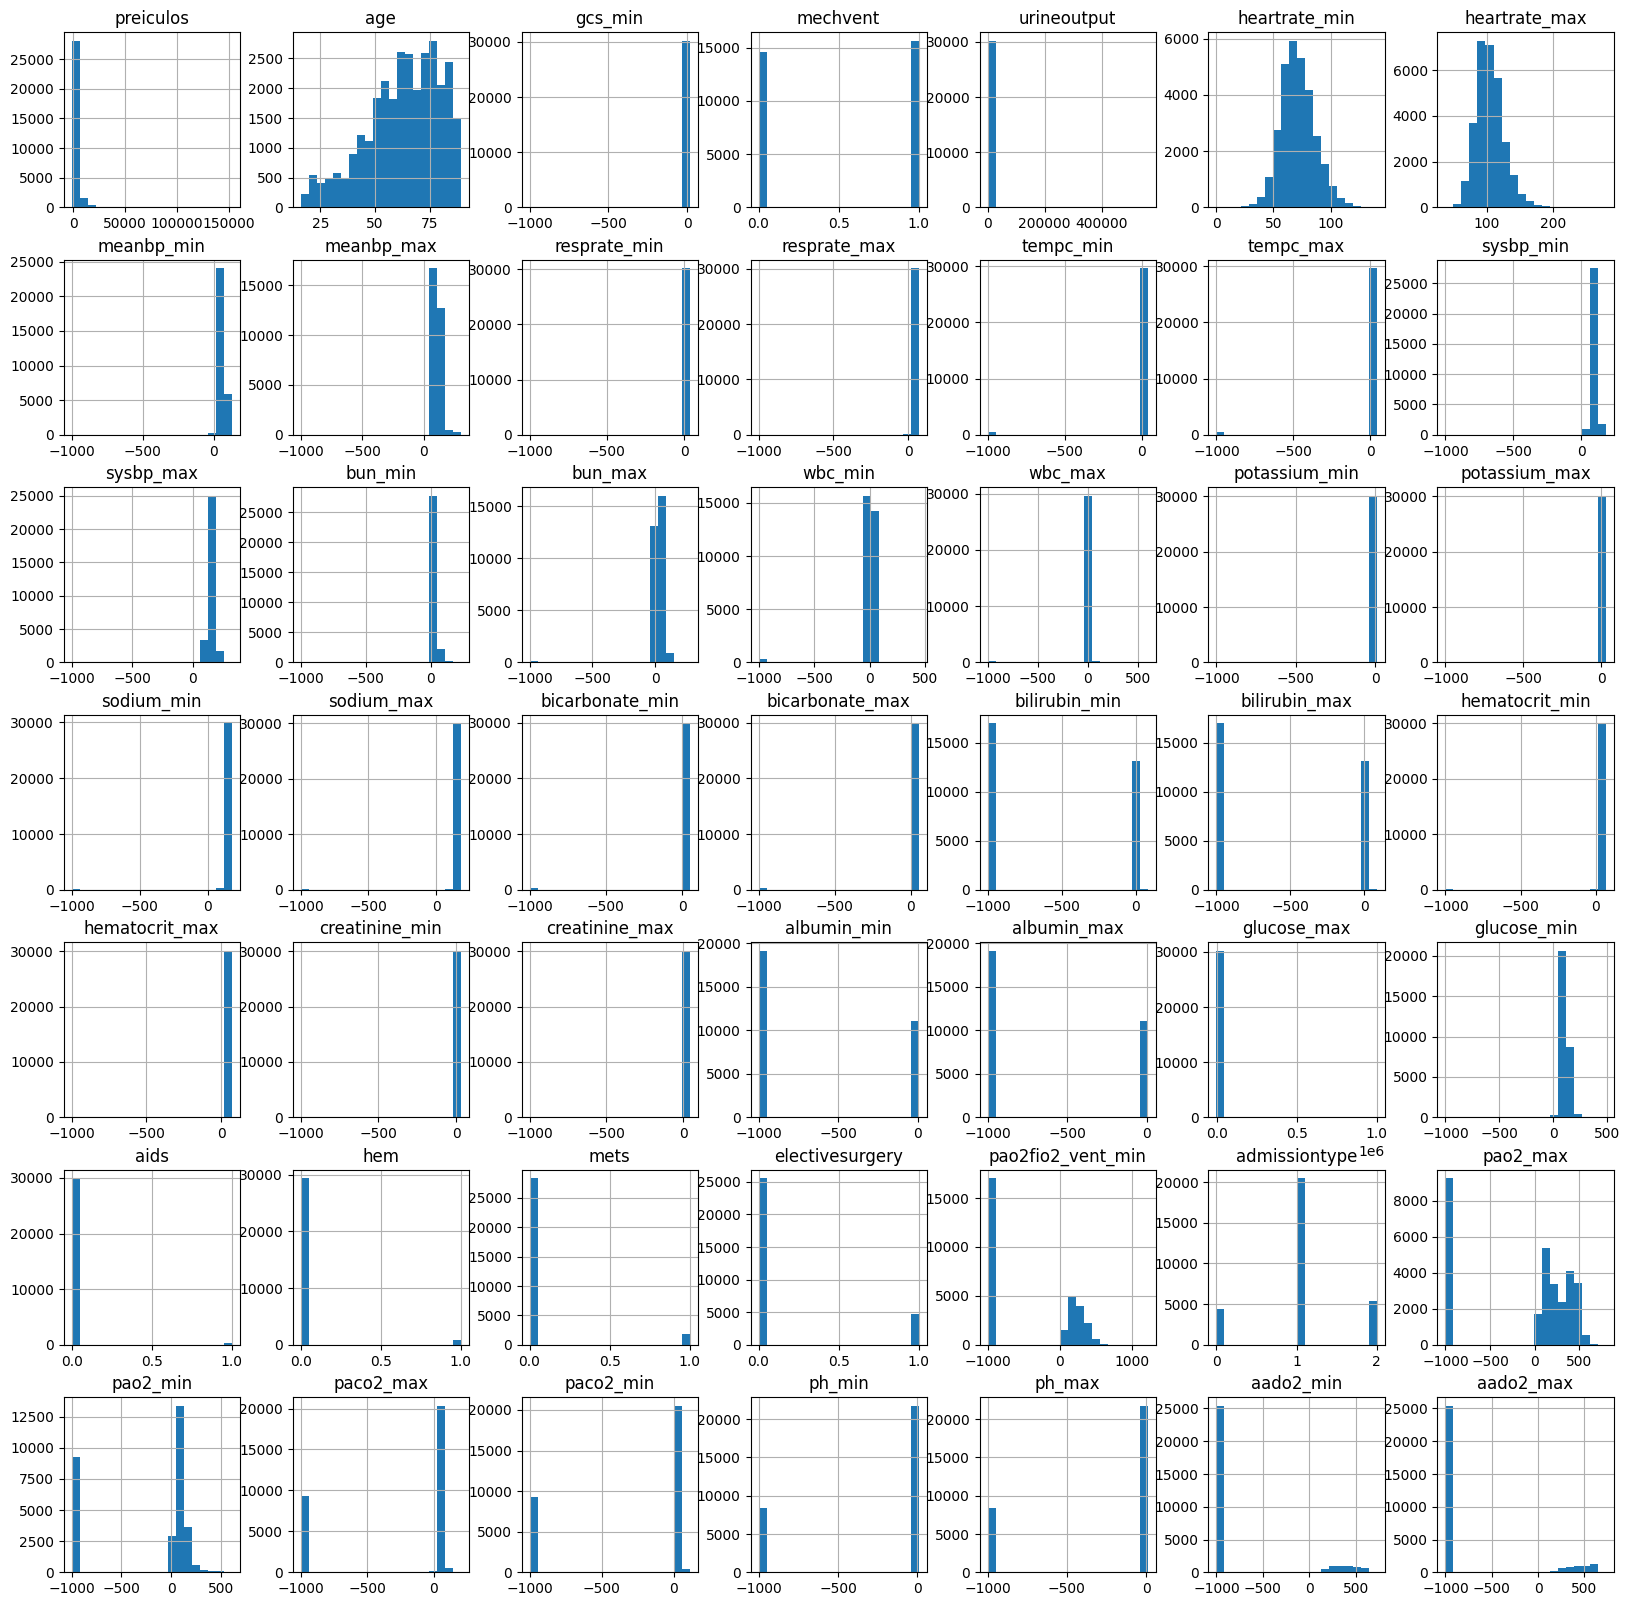

In [63]:
mimic_X.hist(figsize=(20, 20), bins=20);

In [64]:
mimic_y.value_counts()

hospital_expire_flag
0    27090
1     3148
Name: count, dtype: int64

In [70]:
X_train_cont, X_test_cont, y_train_cont, y_test_cont = train_test_split(mimic_X_balanced, mimic_y_balanced, test_size=0.2, random_state=42)

In [71]:
import xgboost as xgb

xgb_model = xgb.XGBClassifier()
xgb_model.fit(X_train_cont, y_train_cont)
xgb_preds = xgb_model.predict(X_test_cont)
from sklearn.metrics import accuracy_score
print(f"XGBoost accuracy: {accuracy_score(y_test_cont, xgb_preds)}")

XGBoost accuracy: 0.7849206349206349


In [74]:
mimic_binarized.to_csv('/home/users/zwb3/research/falling-models/data/MIMIC/mimic_binarized.csv', index=False)